# Historia 3 — Oceny pracowników i Z-score

Wygenerujemy **50 przykładowych ocen pracowników**. Zakładamy średnią **70 punktów** i odchylenie standardowe **15 punktów**.

**Cel:** obliczyć Z-score każdego wyniku, narysować wykres i zaznaczyć pierwszych pięć ocen.

**Z-score** pokazuje, czy wynik jest powyżej czy poniżej średniej i jak daleko od niej leży.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

### Krok 1. Tworzymy przykładowe wyniki
Python losuje 50 ocen pracowników. Ustawiamy stałe losowanie, aby przy każdym uruchomieniu dostawać te same liczby.

In [7]:
generator3 = np.random.default_rng(42)
n3 = 50
wyniki3 = generator3.normal(loc=70.0, scale=15.0, size=n3)

print("Pierwsze 10 wygenerowanych ocen:")
print(np.round(wyniki3[:10], 2))

Pierwsze 10 wygenerowanych ocen:
[74.57 54.4  81.26 84.11 40.73 50.47 71.92 65.26 69.75 57.2 ]


### Krok 2. Obliczamy Z-score
Najpierw sprawdzamy średnią wszystkich ocen, a potem obliczamy Z-score dla każdego pracownika. Wyniki pokazujemy w tabeli.

In [8]:
srednia3 = np.mean(wyniki3)
odchylenie3 = np.std(wyniki3, ddof=1)
z_scores3 = (wyniki3 - srednia3) / odchylenie3

tabela3 = pd.DataFrame({
    "Pracownik": np.arange(1, n3 + 1),
    "Wynik": wyniki3,
    "Z-score": z_scores3,
})

print(f"Średnia z wylosowanej próby: {srednia3:.2f}")
print(f"Odchylenie standardowe próby: {odchylenie3:.2f}")
print("Pierwszych pięciu pracowników:")
display(tabela3.head(5).round(3))
assert np.isclose(np.mean(z_scores3), 0, atol=1e-12)

Średnia z wylosowanej próby: 71.37
Odchylenie standardowe próby: 11.52
Pierwszych pięciu pracowników:


,Pracownik,Wynik,Z-score
0,1,74.571,0.278
1,2,54.400,-1.472
2,3,81.257,0.858
3,4,84.108,1.106
4,5,40.734,-2.658


### Krok 3. Robimy wykres
Wykres pokazuje, jak rozłożyły się oceny po przeliczeniu na Z-score. Na czerwono zaznaczamy i podpisujemy pierwszych pięciu pracowników.

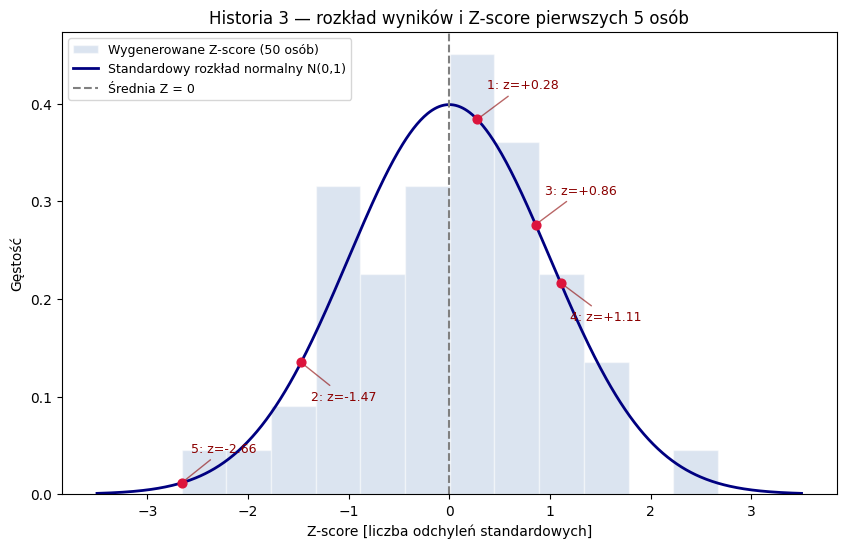

In [9]:
x_wykres3 = np.linspace(-3.5, 3.5, 600)
y_wykres3 = stats.norm.pdf(x_wykres3)

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(z_scores3, bins=12, density=True, alpha=0.45,
        color="lightsteelblue", edgecolor="white", label="Wygenerowane Z-score (50 osób)")
ax.plot(x_wykres3, y_wykres3, color="navy", linewidth=2,
        label="Standardowy rozkład normalny N(0,1)")
ax.axvline(0, color="gray", linestyle="--", label="Średnia Z = 0")

for i in range(5):
    z = z_scores3[i]
    y = stats.norm.pdf(z)
    ax.scatter(z, y, color="crimson", s=40, zorder=5)
    przesuniecie = (7, 22 if i % 2 == 0 else -27)
    ax.annotate(f"{i+1}: z={z:+.2f}", xy=(z, y), xytext=przesuniecie,
                textcoords="offset points", fontsize=9, color="darkred",
                arrowprops={"arrowstyle": "-", "color": "darkred", "alpha": 0.6})

ax.set(title="Historia 3 — rozkład wyników i Z-score pierwszych 5 osób",
       xlabel="Z-score [liczba odchyleń standardowych]", ylabel="Gęstość")
ax.legend(loc="upper left", fontsize=9)
plt.show()

### Wniosek
**Z-score równy 0** oznacza wynik bliski średniej. **Dodatni** oznacza wynik powyżej średniej, a **ujemny** — poniżej średniej. Te wyniki są wygenerowane przez program, nie pochodzą z prawdziwej ankiety.